In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from scipy.special import jv, kn
from scipy.integrate import quad

In [3]:
import sys
sys.path.append('../src/')
from polybessel import PolyBessel

/Users/alexlague/Documents/act/sfb/repo/polybessel/notebooks/../src/polybessel.py:237: SyntaxWarning: invalid escape sequence '\i'
  '''
/Users/alexlague/Documents/act/sfb/repo/polybessel/notebooks/../src/interpolation.py:335: SyntaxWarning: invalid escape sequence '\i'
  '''


In [11]:
sig2 = 5000
f = lambda x: x**2*np.exp(-x**2/sig2)

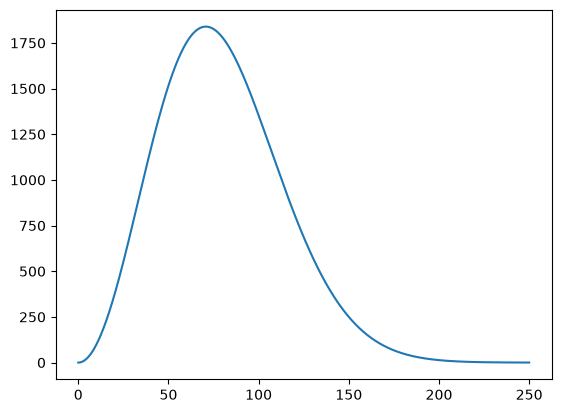

In [12]:
xs = np.linspace(0, 250, 1001)
plt.plot(xs, f(xs))

In [20]:
ks = np.geomspace(0.001, 0.1, 1001)
quad_transform = np.array([quad(lambda x: f(x)*jv(1, k*x), 0.0001, 2000, limit=1000000, epsrel=1e-6, epsabs=1e-6)[0] for k in ks])

In [41]:
PB = PolyBessel(n_cheb_max=256)
pb_transform = PB.compute_many_single_bessel(f, [1], ks, 0.0001, 2000)[0]

In [21]:
%timeit quad_transform = np.array([quad(lambda x: f(x)*jv(1, k*x), 0.0001, 2000, limit=1000000)[0] for k in ks])

314 ms ± 9.82 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [43]:
%timeit pb_transform = PB.compute_many_single_bessel(f, [1], ks, 0.01, 200)[0]

2.84 ms ± 19.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


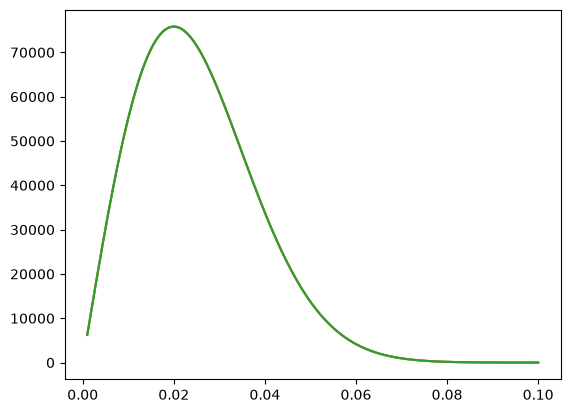

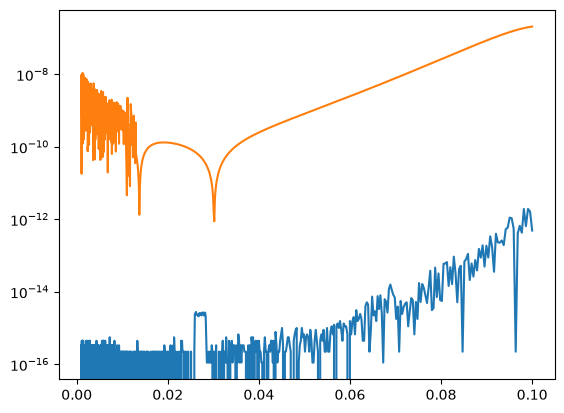

In [42]:
true_transform = ks/(2/sig2)**2*np.exp(-ks**2/4*sig2)
plt.plot(ks, quad_transform)
plt.plot(ks, pb_transform)
plt.plot(ks, true_transform)
#plt.yscale('log')
plt.show()
plt.plot(ks, np.abs(quad_transform/true_transform-1))
plt.plot(ks, np.abs(pb_transform/true_transform-1))

plt.yscale('log')

In [49]:
quad_transform,(lambda k, x: f(x)*k*jv(1, k*x))(.1, 1)

(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 

In [38]:
from scipy import fft
xlog = np.geomspace(1e-4, 1e4, 1024)
dln = np.log(xlog[1]/xlog[0])
mu = 1
offset = fft.fhtoffset(dln, mu)
kfht = np.exp(offset)/xlog[::-1]
scipy_transform = fft.fht(f(xlog), dln, mu, offset=offset) / kfht

(0.0, 0.1)

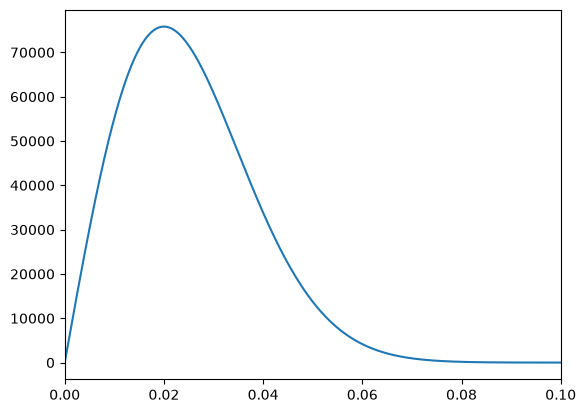

In [36]:
plt.plot(kfht, scipy_transform)
#plt.yscale('log')
#plt.xscale('log')
plt.xlim(0, 0.1)

In [39]:
%timeit fft.fht(f(xlog), dln, mu, offset=offset) / kfht

64.4 μs ± 135 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [89]:
import numpy as np, time
from scipy import fft
from scipy.special import jv, ive

# Test 1: truncated integral with exact answer
a, b, nu = 10., 500., 20
g = lambda x: (x/b)**(nu+1)
exact = lambda k: (jv(nu+1, k*b) - (a/b)**(nu+1)*jv(nu+1, k*a))/k

for n in range(5, 18):
    xlog = np.geomspace(1e-2, 1e5, int(2**n)); dln = np.log(xlog[1]/xlog[0])
    off = fft.fhtoffset(dln, nu); kf = np.exp(off)/xlog[::-1]
    F = fft.fht(np.where((xlog >= a) & (xlog <= b), g(xlog), 0.0), dln, nu, offset=off)/kf
    m = (kf >= 0.01) & (kf <= 1.0); k = kf[m]
    P = PB.compute_many_single_bessel(g, [nu], k, a, b)[0]
    print(2**n, "FFTLog", np.abs(F[m]-exact(k)).max()/np.abs(exact(k)).max(),
          "PolyBessel", np.abs(P-exact(k)).max()/np.abs(exact(k)).max())

32 FFTLog 0.9999475602844392 PolyBessel 1.1006158234837966e-07
64 FFTLog 0.44702671273894684 PolyBessel 6.400453216438655e-08
128 FFTLog 0.551079184614901 PolyBessel 1.0173497794396234e-07
256 FFTLog 0.4855595440623035 PolyBessel 9.970048603406609e-08
512 FFTLog 0.3862668908538971 PolyBessel 1.1510959066304462e-07
1024 FFTLog 0.08367436548738164 PolyBessel 1.1333866653198052e-07
2048 FFTLog 0.07262982785256653 PolyBessel 1.1450439286833416e-07
4096 FFTLog 0.03645318695205305 PolyBessel 1.1481378272842369e-07
8192 FFTLog 0.0014815702382963143 PolyBessel 1.1502211454693782e-07
16384 FFTLog 0.0024143756620150694 PolyBessel 1.1502295578739935e-07
32768 FFTLog 0.004372146091711966 PolyBessel 1.1502472776992573e-07
65536 FFTLog 0.00041220348914715316 PolyBessel 1.150236043062597e-07
131072 FFTLog 8.18235479505953e-05 PolyBessel 1.1502983539416725e-07


In [87]:
2**20

1048576

In [82]:
%timeit PB.compute_many_single_bessel(g, [nu], k[::256], a, b)[0]

397 μs ± 1.35 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [81]:
%timeit fft.fht(np.where((xlog >= a) & (xlog <= b), g(xlog), 0.0), dln, nu, offset=off)/kf

3.52 ms ± 27.9 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


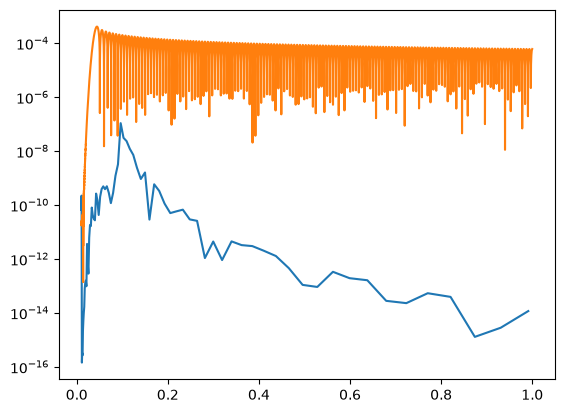

In [83]:
plt.plot(k[::256], np.abs(P[::256]-exact(k[::256]))/np.abs(exact(k[::256])).max())
plt.plot(k, np.abs(F[m]-exact(k))/np.abs(exact(k)).max())
#plt.plot(k, exact(k))
plt.yscale('log')

In [96]:
# Test 2: double Bessel vs Weber's second exponential integral
s, nu = 5000., 10
f2 = lambda x: x*np.exp(-x**2/s)
ks = np.geomspace(0.005, 0.2, 260)
W = s/2*np.exp(-(ks[:, None]-ks[None, :])**2*s/4)*ive(nu, ks[:, None]*ks[None, :]*s/2)
P2 = PB.compute_many_double_bessel(f2, [nu], ks, [nu], ks, 1e-4, 800.)[0, :, 0, :]
print("double", np.abs(P2-W).max()/np.abs(W).max())

double 0.0003279735966221971


In [94]:
from jax import v